# Лабораторная работа №2. СЛАУ: вариант к), II.10.5

$n=10$, $a_{ii}=1$, $a_{ij}=\dfrac{1}{i+j}$ при $i\ne j$, $f_i=\dfrac{1}{i}$.

Все итерации начинаются с нуля. Остановка: $\|f-Ax\|_2/\|f\|_2\le10^{-10}$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

n = 10
i = np.arange(1, n + 1)
A = 1.0 / (i[:, None] + i[None, :])
np.fill_diagonal(A, 1.0)
f = 1.0 / i

tol = 1e-10
max_iter = 1000

def rel_res(x):
    return np.linalg.norm(f - A @ x) / np.linalg.norm(f)

### Свойства матрицы
$A=A^T>0$, диагонального преобладания нет, $\rho(R_J)>1$ — метод Якоби расходится; остальные методы применимы.

In [2]:
lam = np.linalg.eigvalsh(A)
minors = [np.linalg.det(A[:k, :k]) for k in range(1, n + 1)]
off = np.abs(A).sum(axis=1) - np.abs(np.diag(A))
D, L, U = np.diag(np.diag(A)), np.tril(A, -1), np.triu(A, 1)
rho_J = np.max(np.abs(np.linalg.eigvals(-np.linalg.solve(D, L + U))))
rho_S = np.max(np.abs(np.linalg.eigvals(-np.linalg.solve(L + D, U))))

print("A = Aᵀ:", np.allclose(A, A.T))
print(f"λ_min = {lam[0]:.4f}, λ_max = {lam[-1]:.4f}, μ = λ_max/λ_min = {lam[-1] / lam[0]:.4f}")
print("все угловые миноры > 0:", all(m > 0 for m in minors))
print("строки без диагонального преобладания:", [k + 1 for k in range(n) if np.diag(A)[k] <= off[k]])
print(f"ρ(R_J) = {rho_J:.4f}, ρ(R_S) = {rho_S:.4f}")

A = Aᵀ: True
λ_min = 0.6580, λ_max = 2.0484, μ = λ_max/λ_min = 3.1132
все угловые миноры > 0: True
строки без диагонального преобладания: [1, 2, 3, 4]
ρ(R_J) = 1.0484, ρ(R_S) = 0.2224


### 1. Гаусс с выбором главного элемента

In [3]:
def gauss(A, f):
    A = A.astype(float).copy()
    f = f.astype(float).copy()
    n = len(f)

    for k in range(n):
        p = k + np.argmax(np.abs(A[k:, k]))
        if A[p, k] == 0:
            raise ValueError("Матрица вырождена")

        A[[k, p]] = A[[p, k]]
        f[[k, p]] = f[[p, k]]

        for j in range(k + 1, n):
            factor = A[j, k] / A[k, k]
            A[j, k:] -= factor * A[k, k:]
            f[j] -= factor * f[k]

    x = np.zeros(n)
    for k in range(n - 1, -1, -1):
        x[k] = (f[k] - A[k, k + 1:] @ x[k + 1:]) / A[k, k]
    return x

### 2. LU-разложение
Применимо: все угловые миноры отличны от нуля. Решаем последовательно $Ly=f$, затем $Ux=y$.

In [4]:
def lu_solve(A, f):
    n = len(f)
    L = np.eye(n)
    U = np.zeros((n, n))

    for k in range(n):
        for j in range(k, n):
            U[k, j] = A[k, j] - L[k, :k] @ U[:k, j]

        if U[k, k] == 0:
            raise ValueError("LU без перестановок неприменимо")

        for j in range(k + 1, n):
            L[j, k] = (A[j, k] - L[j, :k] @ U[:k, k]) / U[k, k]

    y = np.zeros(n)
    for k in range(n):
        y[k] = f[k] - L[k, :k] @ y[:k]

    x = np.zeros(n)
    for k in range(n - 1, -1, -1):
        x[k] = (y[k] - U[k, k + 1:] @ x[k + 1:]) / U[k, k]
    return x

### 3–5. Якоби, Зейдель и верхняя релаксация
Якоби использует старые значения, Зейдель — уже обновлённые. $\omega$ для SOR подбираем перебором по числу итераций.

In [5]:
def stationary(A, f, method, omega=1.0):
    n = len(f)
    x = np.zeros(n)
    history = [rel_res(x)]

    for _ in range(max_iter):
        if history[-1] <= tol or history[-1] > 1e8:
            break

        old = x.copy()
        for k in range(n):
            if method == "jacobi":
                left = A[k, :k] @ old[:k]
            else:
                left = A[k, :k] @ x[:k]

            right = A[k, k + 1:] @ old[k + 1:]
            value = (f[k] - left - right) / A[k, k]

            if method == "sor":
                x[k] = (1 - omega) * old[k] + omega * value
            else:
                x[k] = value

        history.append(rel_res(x))
    return x, history


omegas = np.round(np.arange(0.1, 1.96, 0.01), 2)
counts = np.array([len(stationary(A, f, "sor", w)[1]) - 1 for w in omegas])
omega = omegas[np.argmin(counts)]
print(f"лучшее ω = {omega:.2f}: {counts.min()} итераций (ω = 1: {counts[np.argmin(np.abs(omegas - 1))]})")

лучшее ω = 0.91: 12 итераций (ω = 1: 15)


### 6–7. Градиентный спуск и минимальные невязки
Обновление $x\leftarrow x+\tau r$, где $r=f-Ax$.
Спуск: $\tau=(r,r)/(Ar,r)$; минимальные невязки: $\tau=(Ar,r)/(Ar,Ar)$.

In [6]:
def descent(A, f, method):
    x = np.zeros(len(f))
    history = [rel_res(x)]

    for _ in range(max_iter):
        if history[-1] <= tol:
            break

        r = f - A @ x
        Ar = A @ r

        if method == "gradient":
            tau = (r @ r) / (Ar @ r)
        else:
            tau = (Ar @ r) / (Ar @ Ar)

        x = x + tau * r
        history.append(rel_res(x))
    return x, history

### 8. Сопряжённые градиенты и BiCGStab

In [7]:
def conjugate_gradient(A, f):
    x = np.zeros(len(f))
    r = f - A @ x
    p = r.copy()
    rr = r @ r
    history = [rel_res(x)]

    for _ in range(max_iter):
        if history[-1] <= tol:
            break

        Ap = A @ p
        alpha = rr / (p @ Ap)
        x = x + alpha * p
        r = r - alpha * Ap

        rr_new = r @ r
        p = r + (rr_new / rr) * p
        rr = rr_new
        history.append(rel_res(x))
    return x, history


def bicgstab(A, f):
    x = np.zeros(len(f))
    r = f - A @ x
    r_hat = r.copy()
    p = r.copy()
    history = [rel_res(x)]

    for _ in range(max_iter):
        if history[-1] <= tol:
            break

        rho = r @ r_hat
        if rho == 0:
            raise ValueError("Срыв BiCGStab: rho = 0")

        Ap = A @ p
        alpha = rho / (Ap @ r_hat)
        s = r - alpha * Ap

        if np.linalg.norm(s) / np.linalg.norm(f) <= tol:
            x = x + alpha * p
            history.append(rel_res(x))
            break

        As = A @ s
        w = (As @ s) / (As @ As)
        if w == 0:
            raise ValueError("Срыв BiCGStab: omega = 0")

        x = x + alpha * p + w * s
        r = s - w * As
        beta = (r @ r_hat) / rho * alpha / w
        p = r + beta * (p - w * Ap)
        history.append(rel_res(x))
    return x, history

### Сравнение
NumPy используется для проверки.

In [8]:
x_ref = np.linalg.solve(A, f)

direct = {
    "Гаусс": gauss(A, f),
    "LU":    lu_solve(A, f),
}
iterative = {
    "Якоби":                 stationary(A, f, "jacobi"),
    "Зейдель":               stationary(A, f, "seidel"),
    f"SOR, ω={omega:.2f}":   stationary(A, f, "sor", omega),
    "Градиентный спуск":     descent(A, f, "gradient"),
    "Минимальные невязки":   descent(A, f, "minres"),
    "Сопряжённые градиенты": conjugate_gradient(A, f),
    "BiCGStab":              bicgstab(A, f),
}

print("Решение:")
print(np.array2string(x_ref, precision=8, suppress_small=True))

print("\nПрямые методы:")
for name, x in direct.items():
    print(f"{name:25s} невязка = {rel_res(x):.3e}")

print("\nИтерационные методы:")
for name, (x, history) in iterative.items():
    status = "сошёлся" if history[-1] <= tol else "не сошёлся"
    print(f"{name:25s} итераций = {len(history) - 1:3d}, невязка = {history[-1]:.3e}, {status}")

Решение:
[ 0.91907711  0.17554017  0.06393482  0.02727476  0.01142347  0.00351084
 -0.00078996 -0.0032508  -0.00469788 -0.00555374]

Прямые методы:
Гаусс                     невязка = 4.171e-17
LU                        невязка = 8.116e-17

Итерационные методы:
Якоби                     итераций = 393, невязка = 1.010e+08, не сошёлся
Зейдель                   итераций =  15, невязка = 3.594e-11, сошёлся
SOR, ω=0.91               итераций =  12, невязка = 8.867e-11, сошёлся
Градиентный спуск         итераций =  30, невязка = 8.088e-11, сошёлся
Минимальные невязки       итераций =  27, невязка = 7.839e-11, сошёлся
Сопряжённые градиенты     итераций =   8, невязка = 4.628e-11, сошёлся
BiCGStab                  итераций =   6, невязка = 4.478e-13, сошёлся


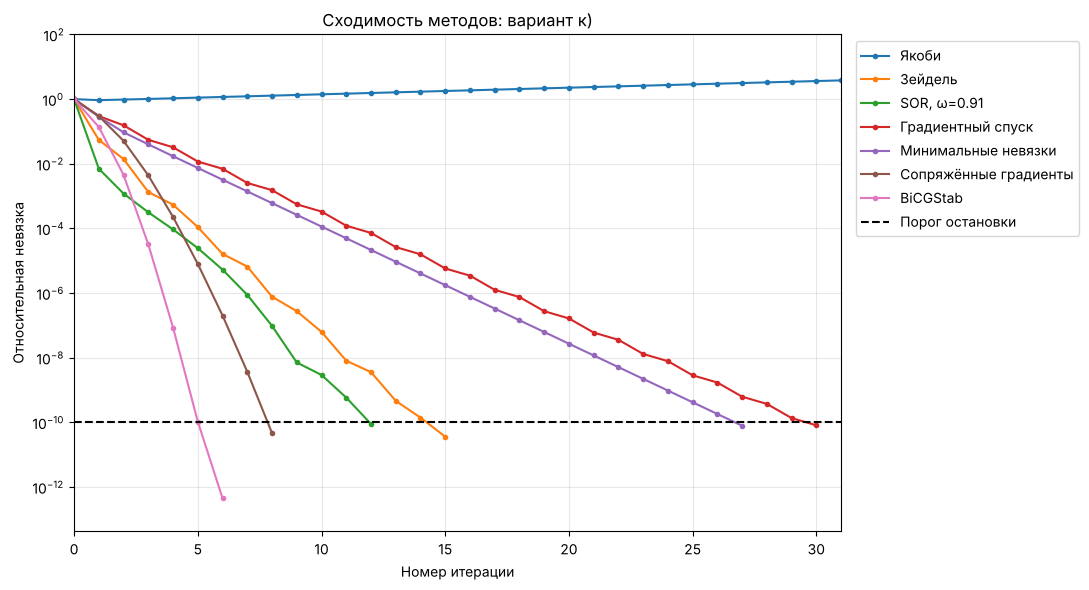

In [9]:
k_max = max(len(h) for name, (x, h) in iterative.items() if h[-1] <= tol)

plt.figure(figsize=(11, 6))
for name, (x, history) in iterative.items():
    plt.semilogy(range(len(history)), history, ".-", label=name)

plt.axhline(tol, color="black", linestyle="--", label="Порог остановки")
plt.xlim(0, k_max)
plt.ylim(top=1e2)
plt.xlabel("Номер итерации")
plt.ylabel("Относительная невязка")
plt.title("Сходимость методов: вариант к)")
plt.grid(True, which="both", alpha=0.3)
plt.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()